# Day 02 — What's Inside a Model
**LLM Inference Engineering · 28-day series**

**Prerequisite:** Day 01. **Goal:** open the model file and see what is physically on disk and in GPU memory.
Only `struct`, `json` and `numpy` are used for parsing. The tokenizer has its own notebook: `Day02_Tokenization.ipynb`.
**Time:** about 25 minutes.

## What is inside a model file?

A model is **not a program**. It is a container of named, numbered arrays (*tensors*). The inference engine (vLLM, TensorRT-LLM, ...) is the program that reads them and does the math.

| You already know | Model equivalent |
|---|---|
| Container image = layers of files | Checkpoint = a set of tensors |
| `Dockerfile` / manifest | `config.json` |
| The runtime that executes it | The inference engine |

A **tensor** is just an N-dimensional array: a number (0-D), a list (1-D), a table (2-D) and so on. A NumPy array with shape `(50257, 768)` *is* a tensor.

In [1]:
import os, json, struct, re, urllib.request
import numpy as np
import matplotlib.pyplot as plt

a = np.zeros((50257, 768), dtype=np.float32)
print("shape :", a.shape, "-> 2-D tensor (a table with 50,257 rows and 768 columns)")
print("bytes :", f"{a.nbytes:,}", " = elements x bytes per element =", f"{a.size:,} x {a.itemsize}")

shape : (50257, 768) -> 2-D tensor (a table with 50,257 rows and 768 columns)
bytes : 154,389,504  = elements x bytes per element = 38,597,376 x 4


## A1. Get GPT-2's files

Hugging Face is "Docker Hub for models". We fetch two files over plain HTTP (about 550 MB, one time only): the weights and the config.

In [2]:
MODEL_DIR = "gpt2_weights"
BASE_URL = "https://huggingface.co/openai-community/gpt2/resolve/main"
FILES = ["config.json", "model.safetensors"]

os.makedirs(MODEL_DIR, exist_ok=True)
for fname in FILES:
    path = os.path.join(MODEL_DIR, fname)
    if not os.path.exists(path):
        print(f"downloading {fname} ...", end=" ", flush=True)
        urllib.request.urlretrieve(f"{BASE_URL}/{fname}", path)
        print("done")
    print(f"  {fname:<20s}{os.path.getsize(path):>15,} bytes")

downloading config.json ... done
  config.json                     665 bytes
downloading model.safetensors ... done
  model.safetensors       548,105,171 bytes


## A2. Read the blueprint: `config.json`

In [3]:
with open(os.path.join(MODEL_DIR, "config.json")) as f:
    config = json.load(f)

L, d, H = config["n_layer"], config["n_embd"], config["n_head"]
V, P = config["vocab_size"], config["n_positions"]
d_ff = config.get("n_inner") or 4 * d

print(f"transformer blocks (n_layer) : {L}")
print(f"hidden width       (n_embd)  : {d}   <- every token is a vector of {d} numbers")
print(f"attention heads    (n_head)  : {H}   (head size {d // H})")
print(f"feed-forward width           : {d_ff}")
print(f"vocabulary         (vocab)   : {V:,}")
print(f"max context   (n_positions)  : {P}")

transformer blocks (n_layer) : 12
hidden width       (n_embd)  : 768   <- every token is a vector of 768 numbers
attention heads    (n_head)  : 12   (head size 64)
feed-forward width           : 3072
vocabulary         (vocab)   : 50,257
max context   (n_positions)  : 1024


## A3. Parse `.safetensors` by hand

The format is deliberately simple:

```
| 8 bytes          | N bytes                         | rest of the file          |
| N as uint64 (LE) | JSON: name -> dtype, shape,     | raw numbers, packed tight |
|                  |       [start, end] byte offsets |                           |
```

Because the header says where every tensor lives, a loader can read **only the header** (instant), and fetch individual tensors on demand. This is why modern formats replaced pickle-based checkpoints.

In [4]:
import time

DTYPES = {"F32": np.float32, "F16": np.float16, "I64": np.int64, "U8": np.uint8}   # numpy has no bfloat16

def read_header(path):
    with open(path, "rb") as f:
        n = struct.unpack("<Q", f.read(8))[0]
        header = json.loads(f.read(n))
    header.pop("__metadata__", None)
    return header, 8 + n

def load_tensor(path, header, data_start, name):
    info = header[name]
    if info["dtype"] not in DTYPES:
        raise NotImplementedError(f"{info['dtype']} needs a library with bfloat16 support")
    start, _end = info["data_offsets"]
    count = int(np.prod(info["shape"])) if info["shape"] else 1
    arr = np.fromfile(path, dtype=DTYPES[info["dtype"]], count=count, offset=data_start + start)
    return arr.reshape(info["shape"])

WEIGHTS = os.path.join(MODEL_DIR, "model.safetensors")
t0 = time.perf_counter()
header, data_start = read_header(WEIGHTS)
ms = (time.perf_counter() - t0) * 1000

print(f"file size      : {os.path.getsize(WEIGHTS)/1e6:,.0f} MB")
print(f"header size    : {data_start:,} bytes")
print(f"header parsed  : {ms:.2f} ms, with no weights read yet")
print(f"tensors listed : {len(header)}")
print("\nfirst entry:", next(iter(header)), "->", next(iter(header.values())))

file size      : 548 MB
header size    : 14,291 bytes
header parsed  : 15.61 ms, with no weights read yet
tensors listed : 160

first entry: h.3.ln_2.bias -> {'dtype': 'F32', 'shape': [768], 'data_offsets': [202420224, 202423296]}


## A4. Inventory: learned weights vs constant buffers

Two kinds of tensors live in the file:
- **Parameters** (learned during training): what people mean by "124M parameters".
- **Buffers**: fixed constants baked in for convenience. GPT-2 stores a causal mask (`attn.bias`) per block.

We can count everything from the header alone.

In [5]:
def numel(shape):
    return int(np.prod(shape)) if shape else 1

def is_buffer(name):
    return name.endswith(".attn.bias") or name.endswith(".attn.masked_bias")   # leading dot: c_attn.bias is a real parameter

params  = {n: i for n, i in header.items() if not is_buffer(n)}
buffers = {n: i for n, i in header.items() if is_buffer(n)}

n_param_elems  = sum(numel(i["shape"]) for i in params.values())
n_buffer_elems = sum(numel(i["shape"]) for i in buffers.values())
tensor_bytes   = sum(i["data_offsets"][1] - i["data_offsets"][0] for i in header.values())

print(f"parameter tensors : {len(params)}")
print(f"buffer tensors    : {len(buffers)}  (causal masks, not learned)")
print(f"learned parameters: {n_param_elems:,}")
print(f"buffer elements   : {n_buffer_elems:,}")
print(f"header + tensors == file size : {data_start + tensor_bytes == os.path.getsize(WEIGHTS)}")

parameter tensors : 148
buffer tensors    : 12  (causal masks, not learned)
learned parameters: 124,439,808
buffer elements   : 12,582,912
header + tensors == file size : True


In [6]:
# Tensor names are a file-system-like path. Show everything outside the repeated blocks, plus block 0.
def show(name):
    i = header[name]
    print(f"  {name:<28s} {str(tuple(i['shape'])):<18s} {numel(i['shape']):>12,}  {i['dtype']}")

print(f"  {'name':<28s} {'shape':<18s} {'elements':>12s}  dtype")
for n in sorted(params):
    if not re.match(r"(transformer\.)?h\.\d+\.", n):
        show(n)
print("  ...")
for n in sorted(params):
    if re.match(r"(transformer\.)?h\.0\.", n):
        show(n)

  name                         shape                  elements  dtype
  ln_f.bias                    (768,)                      768  F32
  ln_f.weight                  (768,)                      768  F32
  wpe.weight                   (1024, 768)             786,432  F32
  wte.weight                   (50257, 768)         38,597,376  F32
  ...
  h.0.attn.c_attn.bias         (2304,)                   2,304  F32
  h.0.attn.c_attn.weight       (768, 2304)           1,769,472  F32
  h.0.attn.c_proj.bias         (768,)                      768  F32
  h.0.attn.c_proj.weight       (768, 768)              589,824  F32
  h.0.ln_1.bias                (768,)                      768  F32
  h.0.ln_1.weight              (768,)                      768  F32
  h.0.ln_2.bias                (768,)                      768  F32
  h.0.ln_2.weight              (768,)                      768  F32
  h.0.mlp.c_fc.bias            (3072,)                   3,072  F32
  h.0.mlp.c_fc.weight          (768, 307

In [7]:
# Prove "12 identical blocks": every block has the same tensor names and shapes.
blocks = {}
for n, i in params.items():
    m = re.match(r"(?:transformer\.)?h\.(\d+)\.(.+)", n)
    if m:
        blocks.setdefault(int(m.group(1)), {})[m.group(2)] = tuple(i["shape"])

print("blocks found:", len(blocks))
print("all blocks identical:", all(b == blocks[0] for b in blocks.values()))
print("tensors per block   :", len(blocks[0]))

blocks found: 12
all blocks identical: True
tensors per block   : 12


## A5. Where do the parameters live?
Like `du -sh` for a model.

In [8]:
def group_of(name):
    if name.endswith("wte.weight"): return "token embeddings (wte)"
    if name.endswith("wpe.weight"): return "position embeddings (wpe)"
    if ".attn." in name:            return "attention"
    if ".mlp." in name:             return "feed-forward (MLP)"
    return "layer norms"

groups = {}
for n, i in params.items():
    groups[group_of(n)] = groups.get(group_of(n), 0) + numel(i["shape"])

total = sum(groups.values())
for g, c in sorted(groups.items(), key=lambda kv: -kv[1]):
    print(f"  {g:<26s}{c:>13,}  {c/total:6.1%}  {'#' * int(c / total * 50)}")

  feed-forward (MLP)           56,669,184   45.5%  ######################
  token embeddings (wte)       38,597,376   31.0%  ###############
  attention                    28,348,416   22.8%  ###########
  position embeddings (wpe)       786,432    0.6%  
  layer norms                      38,400    0.0%  


**Why this matters:** quantization and pruning shrink what is big. In GPT-2 that is the feed-forward and attention matrices. The embedding table is large too, and it is *shared* with the output layer (weight tying), so it is counted once.

### Can we predict the count from `config.json` alone?
If we truly understand the architecture, we can compute it without opening the weights.

In [9]:
emb        = V * d + P * d
attn_block = (d * 3 * d + 3 * d) + (d * d + d)       # QKV projection + output projection (weights + biases)
mlp_block  = (d * d_ff + d_ff) + (d_ff * d + d)      # up projection + down projection
norm_block = 4 * d                                   # two layer norms x (scale + shift)
block      = attn_block + mlp_block + norm_block
predicted  = emb + L * block + 2 * d                 # + final layer norm

print(f"embeddings           : {emb:>13,}")
print(f"one block            : {block:>13,}   (attn {attn_block:,} | mlp {mlp_block:,} | norms {norm_block:,})")
print(f"{L} blocks             : {L * block:>13,}")
print(f"final layer norm     : {2 * d:>13,}")
print(f"predicted total      : {predicted:>13,}")
print(f"counted from file    : {n_param_elems:>13,}")
assert predicted == n_param_elems
print("\nMATCH: the architecture is fully explained by the config.")

embeddings           :    39,383,808
one block            :     7,087,872   (attn 2,362,368 | mlp 4,722,432 | norms 3,072)
12 blocks             :    85,054,464
final layer norm     :         1,536
predicted total      :   124,439,808
counted from file    :   124,439,808

MATCH: the architecture is fully explained by the config.


## A6. Look at real weight values
Weights are plain floats. Their range tells us how much precision we can afford to lose later (Days 13-14).

tensor                          min      max      mean      std
wte.weight                   -1.270    1.785    0.0004    0.144
h.0.attn.c_attn.weight       -2.844    2.796    0.0001    0.200
h.0.mlp.c_fc.weight          -2.313    4.588   -0.0007    0.141
h.11.mlp.c_proj.weight       -9.212    9.146   -0.0004    0.198


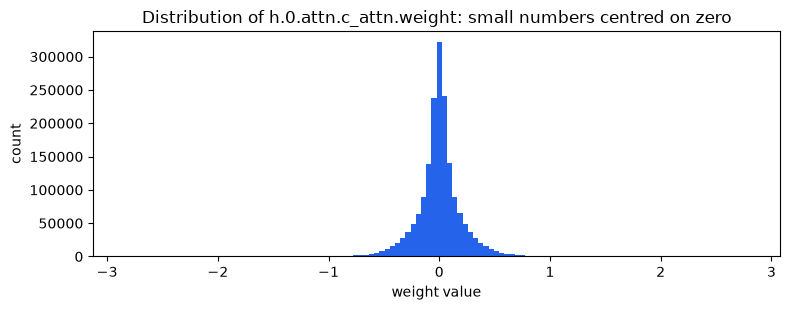

In [10]:
probe = [n for n in ["wte.weight", "h.0.attn.c_attn.weight", "h.0.mlp.c_fc.weight", f"h.{L-1}.mlp.c_proj.weight"] if n in header]
loaded = {n: load_tensor(WEIGHTS, header, data_start, n) for n in probe}

print(f"{'tensor':<26s}{'min':>9s}{'max':>9s}{'mean':>10s}{'std':>9s}")
for n, t in loaded.items():
    print(f"{n:<26s}{t.min():>9.3f}{t.max():>9.3f}{t.mean():>10.4f}{t.std():>9.3f}")

sample = loaded[probe[1]].ravel()
plt.figure(figsize=(8, 3.2))
plt.hist(sample, bins=120, color="#2563eb")
plt.title(f"Distribution of {probe[1]}: small numbers centred on zero")
plt.xlabel("weight value"); plt.ylabel("count")
plt.tight_layout(); plt.show()

## A7. Weights decide your GPU memory bill
Memory for weights = parameters x bytes per parameter. This is the first number you check before choosing a GPU.
(KV cache and activations come on top: Day 05.)

In [11]:
bytes_per = {"FP32": 4, "FP16/BF16": 2, "FP8/INT8": 1, "INT4": 0.5}
models = {"GPT-2 (this file)": n_param_elems, "8B-class model": 8e9, "70B-class model": 70e9}
GPU_GB = 80

print(f"{'model':<20s}" + "".join(f"{k:>13s}" for k in bytes_per) + f"   fits one {GPU_GB} GB GPU at FP16?")
for name, n in models.items():
    row = "".join(f"{n * b / 1e9:>10.1f} GB" for b in bytes_per.values())
    fits = "yes" if n * 2 / 1e9 < GPU_GB else "no, needs quantization or several GPUs"
    print(f"{name:<20s}{row}   {fits}")

model                        FP32    FP16/BF16     FP8/INT8         INT4   fits one 80 GB GPU at FP16?
GPT-2 (this file)          0.5 GB       0.2 GB       0.1 GB       0.1 GB   yes
8B-class model            32.0 GB      16.0 GB       8.0 GB       4.0 GB   yes
70B-class model          280.0 GB     140.0 GB      70.0 GB      35.0 GB   no, needs quantization or several GPUs


## Recap
- A checkpoint is a JSON header plus raw numbers. We parsed it with `struct` and `numpy`.
- GPT-2 has 124,439,808 learned parameters in 148 tensors (plus 12 constant causal masks): embeddings, 12 identical blocks, a final norm.
- Feed-forward is the largest part (about 46%), then token embeddings (about 31%), then attention (about 23%).
- Parameters x bytes per parameter = weight memory. That one multiplication sizes your GPU.